# Lab Neural Networks

Save the notebook as either PDF or HTML and make sure all the results are saved correctly (I won't run them and the original format does not save the results automatically), **and put your name in the filename**.

<div class="alert alert-success">
<b>Questions are in green boxes.</b>
The maximum time you should spend on each question is given as indication only. If you take more time than that, then you should come see me.
</div>
<div class="alert alert-info" role="alert"><b>Analyzes are in blue boxes.</b> You should comment on your results in theses boxes (Is it good? Is it expected? Why do we get such result? Why is it different from the previous one? etc)
</div>

This lab needs a GPU runtime (on Colab: `Runtime > Change runtime type > T4 GPU`). None of the models is large, but the whole notebook trains a few dozen networks: expect roughly 20-30 minutes in total. Q6 (batch size 1 and 2), Q10 (deep networks) and Q11 are the longest.

**How to read the results.** Every configuration is trained once (seed 3407), and the validation set has only 300 images: an accuracy difference below 2 points is within noise. Whenever you compare two settings, look at the *whole loss curves* (speed of convergence, stability, gap between train and validation) rather than at a single final number, and prefer the validation **loss** to the validation accuracy to rank configurations: it is much less noisy.

**Hyper-parameters matter.** In this lab, the conclusions of chapters 6 and 7 only appear if each technique is used with a sensible setting, and the questions tell you the main trap of each one (for instance, how the learning rate must change when you change the batch size, or when you add momentum).

**Code.** The cells with a `# TODO` are for you to complete; the other ones are provided and should be run as is. The outputs displayed under the cells are those of a reference solution, to compare your results to: they are replaced by yours when you run the cells, and small differences are normal. Some TODO cells tell you the names of the variables to keep, because the cells below use them.

In [1]:
import time
import math
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from torch.utils.flop_counter import FlopCounterMode

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

SEED = 3407  # https://arxiv.org/abs/2109.08203

def set_seed(seed=SEED):
    torch.manual_seed(seed)
    np.random.seed(seed)
    torch.cuda.manual_seed_all(seed)

set_seed()

device: cuda


For this lab, we will use the bluebell dataset, as in Lab 1. Training a neural network is far more costly than a linear model, so we only use **split 0** for the rest of this lab, instead of the five splits of Lab 1. Images are kept at full resolution ($64\times 64\times 3$), rescaled to $[-1, 1]$ as in Lab 1, and given to the models as images, not flattened vectors.

Chance level for 12 balanced classes is an accuracy of $1/12 \approx 0.083$.

train: torch.Size([1200, 3, 64, 64]) val: torch.Size([300, 3, 64, 64])
label: 0


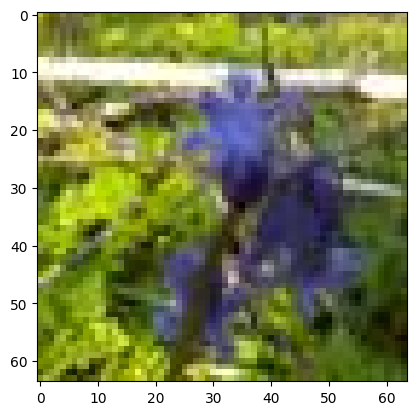

In [2]:
from bluebell import Bluebell

def load_split(mode, split=0):
    ds = Bluebell('bluebell_64', mode, split=split)
    X = np.array([img for img, lab in ds], dtype=np.float32) / 127.5 - 1.
    y = np.array([lab for img, lab in ds], dtype=np.int64)
    X = torch.from_numpy(X).permute(0, 3, 1, 2).contiguous()  # (N, 3, 64, 64)
    y = torch.from_numpy(y)
    return X, y

X_train, y_train = load_split('train', split=0)
X_val, y_val = load_split('val', split=0)
X_train, y_train = X_train.to(device), y_train.to(device)
X_val, y_val = X_val.to(device), y_val.to(device)

print("train:", X_train.shape, "val:", X_val.shape)
plt.imshow(X_train[0].permute(1, 2, 0).cpu() / 2 + 0.5)
print("label:", y_train[0].item())

## Training loop

Every question in this lab trains a `torch.nn.Module` with a `torch.optim` optimizer and the cross-entropy loss, the standard recipe for a classifier. Rather than repeating it, we factor it once into `evaluate` (loss and accuracy on a full dataset, in batches to bound memory) and `train_model` (one call: loops over epochs, optionally steps a learning-rate `scheduler` after every batch, and calls `evaluate` after each epoch). Every question below only has to build a model and an optimizer, then call `train_model`. `compare` and `summarize` are there to put several runs side by side.

In [3]:
@torch.no_grad()
def evaluate(model, X, y, batch_size=128):
    model.eval()
    total_loss, total_correct = 0., 0
    for start in range(0, X.shape[0], batch_size):
        xb, yb = X[start:start + batch_size], y[start:start + batch_size]
        logits = model(xb)
        total_loss += F.cross_entropy(logits, yb, reduction="sum").item()
        total_correct += (logits.argmax(dim=1) == yb).sum().item()
    n = X.shape[0]
    return total_loss / n, total_correct / n


def train_model(model, optimizer, epochs, batch_size=64, scheduler=None, log_every=10, eval_every=1):
    '''
    Trains `model` with `optimizer` for `epochs` passes over (X_train, y_train).
    `scheduler` (if any) is stepped after every batch. Train/val loss and accuracy
    are recorded every `eval_every` epochs (and at the last one).
    '''
    n_train = X_train.shape[0]
    h = {k: [] for k in ["epoch", "train_loss", "train_acc", "val_loss", "val_acc", "lr"]}
    t0 = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        perm = torch.randperm(n_train, device=device)
        for start in range(0, n_train, batch_size):
            idx = perm[start:start + batch_size]
            optimizer.zero_grad()
            loss = F.cross_entropy(model(X_train[idx]), y_train[idx])
            loss.backward()
            optimizer.step()
            if scheduler is not None:
                scheduler.step()

        if epoch % eval_every == 0 or epoch == epochs:
            tr_loss, tr_acc = evaluate(model, X_train, y_train)
            va_loss, va_acc = evaluate(model, X_val, y_val)
            for k, v in zip(h, [epoch, tr_loss, tr_acc, va_loss, va_acc, optimizer.param_groups[0]["lr"]]):
                h[k].append(v)
            if log_every and (epoch % log_every == 0 or epoch == epochs):
                print(f"epoch {epoch:3d}: train loss={tr_loss:.3f} acc={tr_acc:.3f} | val loss={va_loss:.3f} acc={va_acc:.3f}")
    h["time"] = time.time() - t0
    return h


def count_parameters(model):
    return sum(p.numel() for p in model.parameters() if p.requires_grad)


def plot_history(history, title=""):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    axes[0].plot(history["epoch"], history["train_loss"], label="train")
    axes[0].plot(history["epoch"], history["val_loss"], label="val")
    axes[0].set_xlabel("epoch"); axes[0].set_ylabel("cross-entropy loss"); axes[0].legend()
    axes[1].plot(history["epoch"], history["train_acc"], label="train")
    axes[1].plot(history["epoch"], history["val_acc"], label="val")
    axes[1].set_xlabel("epoch"); axes[1].set_ylabel("accuracy"); axes[1].legend()
    fig.suptitle(title)
    fig.tight_layout()


def compare(histories, keys=("train_loss", "val_loss"), ylog=False):
    '''Plots the same curves for several runs; `histories` maps a run name to its history.'''
    fig, axes = plt.subplots(1, len(keys), figsize=(5 * len(keys), 4))
    for ax, key in zip(np.atleast_1d(axes), keys):
        for name, h in histories.items():
            ax.plot(h["epoch"], h[key], label=name)
        ax.set_xlabel("epoch"); ax.set_title(key); ax.legend(fontsize=8)
        if ylog:
            ax.set_yscale("log")
    fig.tight_layout()


def summarize(name, h, thr=0.3):
    '''
    One line per run: final accuracies, final val loss, how many epochs it took to get the train loss
    under `thr` (speed), and the std of the val loss over the last 20 epochs (stability).
    '''
    tl = np.array(h["train_loss"])
    reach = h["epoch"][int(np.argmax(tl < thr))] if (tl < thr).any() else None
    print(f"{name:<30} train acc={h['train_acc'][-1]:.3f} | val acc={h['val_acc'][-1]:.3f} | val loss={h['val_loss'][-1]:.3f} | "
          f"epochs to train loss<{thr}: {reach} | std val loss (last 20): {np.std(h['val_loss'][-20:]):.3f} | {h['time']:.0f}s")

## Multi-layer perceptron

We first try the simplest neural network: a multi-layer perceptron (MLP) directly on the flattened pixels, as in Lab 1's linear models. An MLP ignores the 2D structure of an image entirely, treating a pixel in a corner exactly like a pixel in the middle.

Throughout the first part of the lab we use **plain SGD with a learning rate of 0.03** and no normalization (the networks are small, and this value is the largest that trains them stably).

<div class="alert alert-success"> <b>Q1.</b> Implement a 2-hidden-layer MLP (<code>nn.Module</code>) that takes a flattened image as input and outputs 12 class logits. Train it with plain <code>SGD</code> (<code>lr=0.03</code>, no momentum) and the cross-entropy loss for 60 epochs. Report the final train/val accuracy, the training time, and the number of parameters.
</div>

In [4]:
LR_SGD = 0.03

class MLP(nn.Module):
    def __init__(self, n_classes=12, in_dim=64 * 64 * 3, hidden=256):
        super().__init__()
        # TODO: flatten the image, then 2 hidden layers of size `hidden` with ReLU, then the output layer
        self.net = None

    def forward(self, x):
        # TODO:
        pass

epoch  10: train loss=0.644 acc=0.783 | val loss=0.971 acc=0.623


epoch  20: train loss=0.363 acc=0.867 | val loss=0.968 acc=0.653


epoch  30: train loss=0.053 acc=0.997 | val loss=0.674 acc=0.760


epoch  40: train loss=0.021 acc=1.000 | val loss=0.703 acc=0.763


epoch  50: train loss=0.012 acc=1.000 | val loss=0.737 acc=0.757


epoch  60: train loss=0.008 acc=1.000 | val loss=0.766 acc=0.753

parameters: 3,214,860
CPU times: user 2.29 s, sys: 203 ms, total: 2.5 s
Wall time: 2.56 s


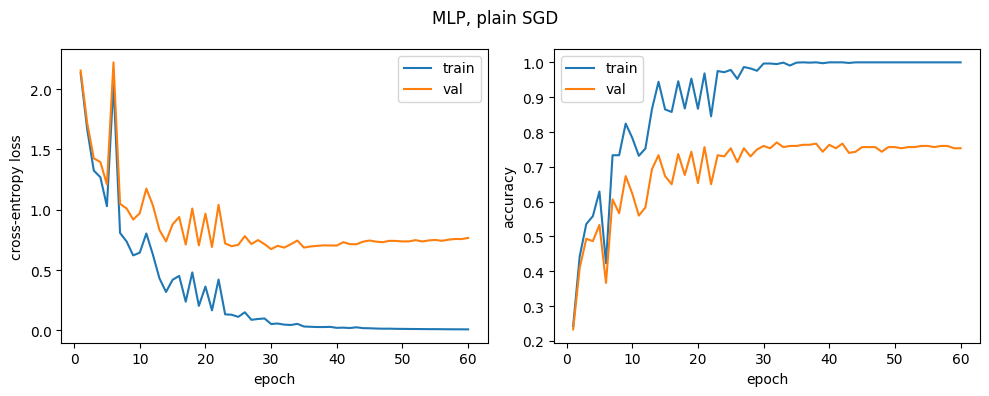

In [5]:
%%time
# TODO: set the seed (set_seed()), build the model (keep the name `mlp`), a plain SGD optimizer with lr=LR_SGD,
# and train for 60 epochs with train_model (keep the name `history_mlp` for the returned history)

# TODO: print the number of parameters (count_parameters) and plot the curves (plot_history)

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>How many parameters does the MLP have, compared to the 1200 training images? What are the final train and validation accuracies? Does the train/val gap suggest overfitting?</li>
<li>Given chapter 6's equivariance argument, is this architecture the right prior for image data, independently of how much data we have? What would happen to the MLP if the flower was shifted by a few pixels in every test image?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## Convolutional neural network

A convolution shares the same small filter across every spatial location: this builds in translation equivariance (chapter 6) instead of hoping the MLP learns it from data. We now replace the MLP with a small CNN: 3 blocks of (convolution, ReLU, max-pooling), followed by a linear classifier on the pooled features. Every later question in this lab modifies this architecture or its training; keep it close at hand.

<div class="alert alert-success"> <b>Q2.</b> Implement a <code>SmallCNN</code> with 3 blocks of (<code>Conv2d</code> 3x3, <code>ReLU</code>, <code>MaxPool2d</code> 2x2), channel widths 16, 32, 64, followed by a linear classifier. Train it with the exact same optimizer and number of epochs as Q1 (plain SGD, <code>lr=0.03</code>, 60 epochs). Compare its parameter count, training time and accuracy to the MLP's.
</div>

In [6]:
class LayerNorm2d(nn.Module):
    '''
    LayerNorm of chapter 7 applied to an image: the statistics are computed over the channels of each
    pixel (the last dimension of a channels-last tensor), independently for each pixel and each sample.
    There is no dependency on the batch.
    '''

    def __init__(self, n_channels, eps=1e-5):
        super().__init__()
        self.eps = eps
        self.gamma = nn.Parameter(torch.ones(n_channels))
        self.beta = nn.Parameter(torch.zeros(n_channels))

    def forward(self, x):
        x = x.permute(0, 2, 3, 1)  # (N, H, W, C)
        mean = x.mean(dim=-1, keepdim=True)
        var = x.var(dim=-1, unbiased=False, keepdim=True)
        x = self.gamma * (x - mean) / torch.sqrt(var + self.eps) + self.beta
        return x.permute(0, 3, 1, 2)


class SmallCNN(nn.Module):
    '''
    3 x (conv, [norm], ReLU, maxpool), then a linear classifier on the pooled features. `dropout_p` and `norm`
    are unused in Q2: they are here so that later questions (Q4 for dropout, Q5/Q6 for normalization) only pass
    a different argument, instead of redefining the class.
    '''

    def __init__(self, n_classes=12, channels=(16, 32, 64), dropout_p=0.0, norm=None):
        super().__init__()
        # TODO: for each width in `channels`: Conv2d 3x3 (padding=1), then a BatchNorm2d if norm == "batch" or a LayerNorm2d
        # if norm == "layer", then ReLU, then MaxPool2d(2). Put the layers in the nn.Sequential `self.features`.
        # (the `norm` argument is only used from Q5 on: you can add it now or come back to it)
        self.features = None
        # TODO: a dropout layer (`dropout_p`, applied just before the classifier) and a linear classifier on the flattened
        # features (after 3 poolings, a 64x64 image is 8x8)
        self.dropout = None
        self.classifier = None

    def forward(self, x):
        # TODO:
        pass

epoch  10: train loss=0.847 acc=0.667 | val loss=1.082 acc=0.580


epoch  20: train loss=0.462 acc=0.824 | val loss=0.856 acc=0.670


epoch  30: train loss=0.150 acc=0.953 | val loss=0.627 acc=0.803


epoch  40: train loss=0.036 acc=0.998 | val loss=0.539 acc=0.863


epoch  50: train loss=0.043 acc=0.994 | val loss=0.667 acc=0.827


epoch  60: train loss=0.007 acc=1.000 | val loss=0.675 acc=0.830

parameters: 72,748 (MLP had 3,214,860)


CPU times: user 5.5 s, sys: 86.1 ms, total: 5.59 s
Wall time: 5.64 s


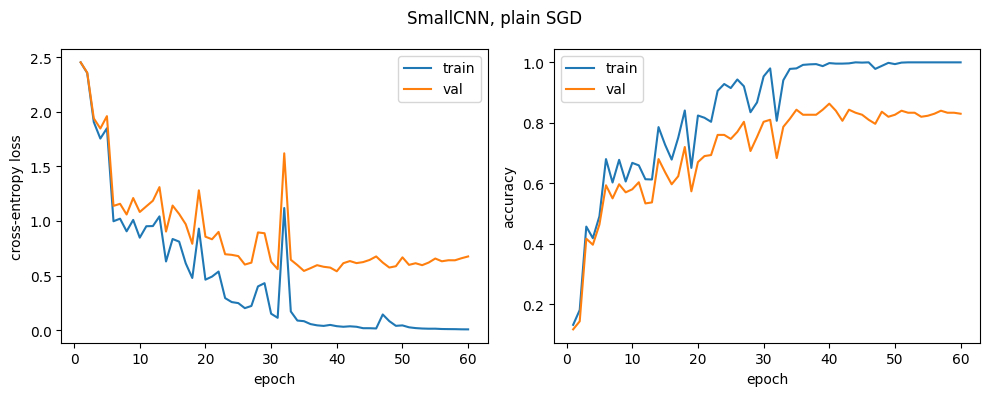

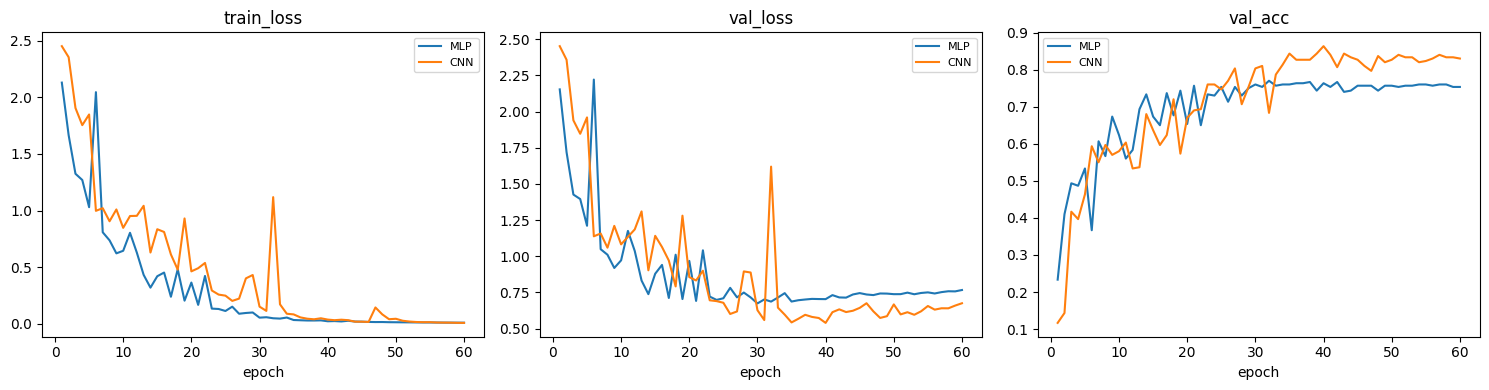

In [7]:
%%time
# TODO: same as Q1 with the SmallCNN, same optimizer, same number of epochs (keep the names `cnn` and `history_cnn`)

# TODO: print the number of parameters of both models, and compare the two runs on the same plots
# (hint: compare({"MLP": history_mlp, "CNN": history_cnn}, keys=("train_loss", "val_loss", "val_acc")) )

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Compare the parameter count and the validation accuracy to the MLP. Which model has the better accuracy, by how much, and is the difference larger than the noise (~2 points)?</li>
<li>Both networks reach (almost) 100% train accuracy. Which one overfits more, judging from the validation loss curves? Is a convolution's weight sharing a form of regularization, independently of any penalty on the loss?</li>
<li>From here on, we keep the CNN and drop the MLP entirely.</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## Regularization

The CNN above reaches 100% training accuracy with a training loss close to zero, while its validation loss gets worse and worse: it memorizes the 1200 training images. We now train it for longer, and see whether weight decay and dropout keep that in check.

**A remark on model selection.** The validation set only has 300 images, so the validation accuracy is a coarse and noisy measure (one image is 0.33%). In this lab we select hyper-parameters with the **validation loss** at the end of training.

<div class="alert alert-success"> <b>Q3.</b> Retrain your <code>SmallCNN</code> (same architecture as Q2) for 80 epochs, plain SGD (<code>lr=0.03</code>), and compare <code>weight_decay</code> in $\{0, 10^{-4}, 10^{-3}, 10^{-2}, 10^{-1}\}$. Plot the loss curves (train and validation) and report the final val loss and accuracy for each value. Keep the value with the lowest final validation loss.
</div>

weight_decay=0.0               train acc=1.000 | val acc=0.833 | val loss=0.751 | epochs to train loss<0.3: 23 | std val loss (last 20): 0.024 | 7s


weight_decay=0.0001            train acc=1.000 | val acc=0.847 | val loss=0.735 | epochs to train loss<0.3: 23 | std val loss (last 20): 0.021 | 7s


weight_decay=0.001             train acc=1.000 | val acc=0.863 | val loss=0.695 | epochs to train loss<0.3: 23 | std val loss (last 20): 0.020 | 7s


weight_decay=0.01              train acc=1.000 | val acc=0.860 | val loss=0.530 | epochs to train loss<0.3: 24 | std val loss (last 20): 0.025 | 7s


weight_decay=0.1               train acc=0.817 | val acc=0.707 | val loss=0.869 | epochs to train loss<0.3: None | std val loss (last 20): 0.124 | 7s

best weight_decay (lowest val loss): 0.01
CPU times: user 34.4 s, sys: 138 ms, total: 34.6 s
Wall time: 34.9 s


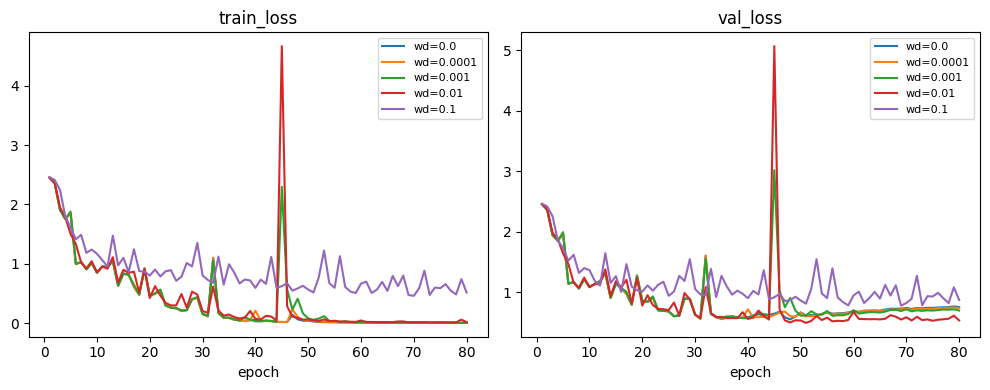

In [8]:
%%time
wd_grid = [0.0, 1e-4, 1e-3, 1e-2, 1e-1]
wd_histories = {}
# TODO: for each weight decay: set the seed, build a SmallCNN, an SGD optimizer (lr=LR_SGD, weight_decay=wd), train for
# 80 epochs (log_every=0 silences the per-epoch print), store the history in wd_histories[wd] and print summarize(...)

# TODO: plot the runs together with compare(...), and keep in `best_wd` the weight decay with the lowest final val loss

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Does the training loss keep decreasing regardless of <code>weight_decay</code>, while the validation loss does not? What does the validation loss do for <code>weight_decay=0</code> after a few epochs, and what does it tell you?</li>
<li>At which value does weight decay start to hurt the training loss noticeably (underfitting)? What is the best value, and how much does it improve the validation loss and the validation accuracy? Is the improvement in accuracy larger than the noise?</li>
<li>Chapter 7 explains that with a loss that never vanishes, the weights of the features correlated with the label keep growing. How does weight decay counteract that? Keep the best value (<code>best_wd</code>) for the rest of the lab.</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

<div class="alert alert-success"> <b>Q4.</b> Using the <code>dropout_p</code> argument of your <code>SmallCNN</code> (applied just before the final linear layer) and <code>best_wd</code> from Q3, sweep <code>dropout_p</code> in $\{0, 0.2, 0.5, 0.8, 0.9\}$ for 80 epochs. Compare to the run of Q3 with weight decay alone (<code>dropout_p=0</code>). Keep the value with the lowest final validation loss.
</div>

dropout_p=0.0                  train acc=1.000 | val acc=0.857 | val loss=0.548 | epochs to train loss<0.3: 24 | std val loss (last 20): 0.020 | 7s


dropout_p=0.2                  train acc=1.000 | val acc=0.870 | val loss=0.443 | epochs to train loss<0.3: 25 | std val loss (last 20): 0.042 | 7s


dropout_p=0.5                  train acc=0.998 | val acc=0.883 | val loss=0.390 | epochs to train loss<0.3: 25 | std val loss (last 20): 0.131 | 8s


dropout_p=0.8                  train acc=0.994 | val acc=0.920 | val loss=0.287 | epochs to train loss<0.3: 30 | std val loss (last 20): 0.115 | 7s


dropout_p=0.9                  train acc=0.968 | val acc=0.917 | val loss=0.298 | epochs to train loss<0.3: 34 | std val loss (last 20): 0.045 | 7s

best dropout_p (lowest val loss): 0.8 (combined with weight_decay=0.01)
CPU times: user 35.6 s, sys: 200 ms, total: 35.8 s
Wall time: 36.3 s


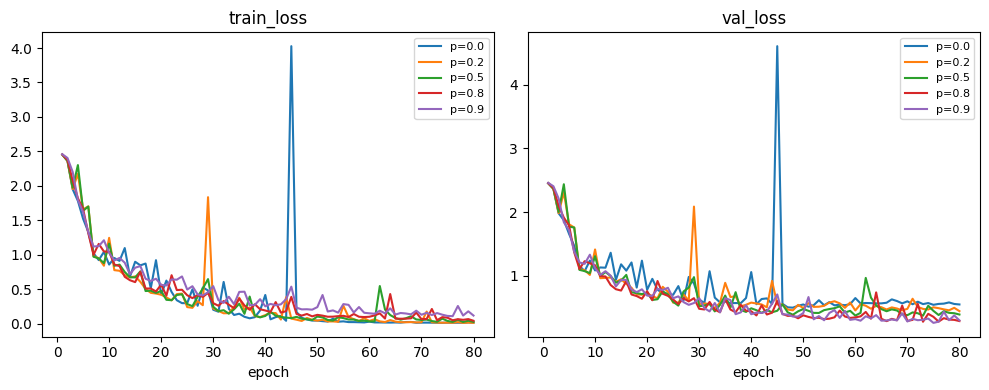

In [9]:
%%time
dropout_grid = [0.0, 0.2, 0.5, 0.8, 0.9]
dropout_histories = {}
# TODO: same as Q3, for each dropout_p (with weight_decay=best_wd), history in dropout_histories[p]

# TODO: compare the runs, and keep in `best_dropout` the dropout_p with the lowest final val loss

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Does dropout on top of weight decay help further, or does it mostly duplicate the same effect? Support your answer with the validation loss and the validation accuracy.</li>
<li>How does the training loss (and the number of epochs needed to fit the training set) change when <code>dropout_p</code> increases? Is there a value that clearly hurts, i.e., underfits? How do you see it in the validation loss?</li>
<li>Dropout is applied on a 4096-dimensional feature vector feeding a 12-way linear classifier. Why is a large <code>dropout_p</code> acceptable here, and would it be as acceptable on a 16-dimensional feature vector?</li>
<li>Keep the best combination (<code>best_wd</code>, <code>best_dropout</code>) for the rest of the lab.</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## Normalization

We now add normalization layers to the CNN. Both BatchNorm and LayerNorm (chapter 7) rescale a layer's activations to a controlled mean and variance; they differ only in which axis the statistics are computed over: BatchNorm over the batch (and the spatial positions), LayerNorm, for an image, over the channels of each pixel, independently for each sample.

<div class="alert alert-success"> <b>Q5.</b> Using the <code>norm="batch"</code> argument of your <code>SmallCNN</code> (one <code>BatchNorm2d</code> per convolution, combined with the best regularization found in Q4), retrain for 80 epochs with plain SGD, same learning rate as before. Compare the curves to the best run of Q4.
</div>

no norm (Q4)                   train acc=0.994 | val acc=0.920 | val loss=0.287 | epochs to train loss<0.3: 30 | std val loss (last 20): 0.115 | 7s
BatchNorm                      train acc=0.995 | val acc=0.950 | val loss=0.155 | epochs to train loss<0.3: 9 | std val loss (last 20): 0.193 | 9s
CPU times: user 9.73 s, sys: 53.9 ms, total: 9.78 s
Wall time: 9.84 s


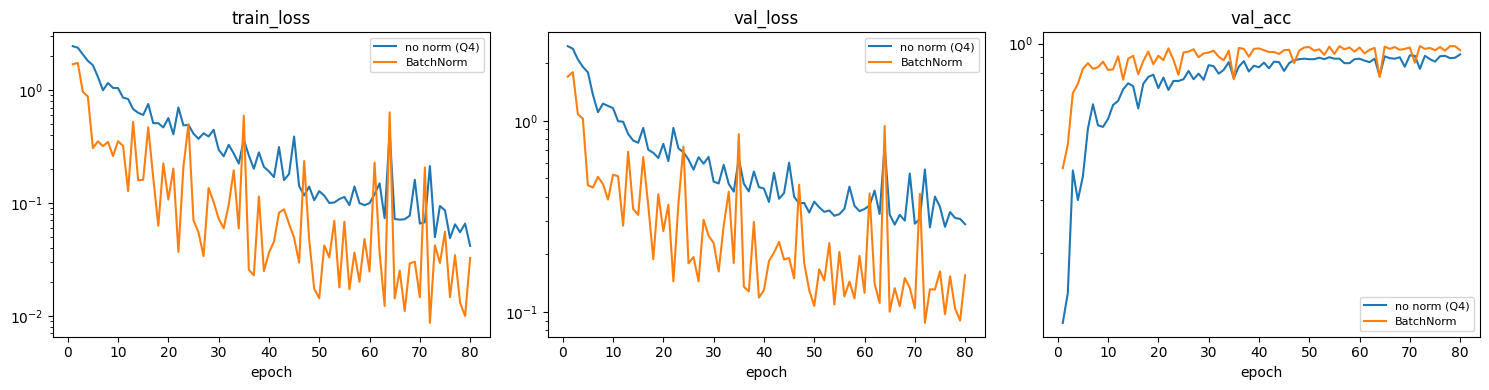

In [10]:
%%time
# TODO: train the SmallCNN with norm="batch", dropout_p=best_dropout, SGD(lr=LR_SGD, weight_decay=best_wd), 80 epochs
# (keep the name `history_bn` for the history)

# TODO: compare it to the best run of Q4, dropout_histories[best_dropout] (a log scale helps: compare(..., ylog=True)),
# and print summarize(...) for both runs

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Does BatchNorm reach a given training loss in fewer epochs than the un-normalized network (chapter 7's stability argument)? Give the numbers.</li>
<li>Does it change the final validation accuracy, or mostly the speed of getting there? Is the change larger than the noise?</li>
<li>BatchNorm makes the network insensitive to the scale of its weights and of its input features. Why does that allow the use of a larger learning rate? (you do not have to test it)</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

BatchNorm uses the statistics of the current batch during training, and a running average of them (an exponential moving average, chapter 7) at test time. Chapter 7 points out that this prevents training with a small batch size. LayerNorm uses statistics computed on each sample alone, and is therefore independent of the batch size. We check this by training with smaller and smaller batches.

**A trap when changing the batch size.** With a batch of size $B$, one epoch contains $1200/B$ updates: a batch of 1 makes 64 times more updates per epoch than a batch of 64. If you keep the same learning rate, the small-batch run makes much larger total steps (and more of them) and the comparison is meaningless. The usual remedy is the *linear scaling rule*: use a learning rate proportional to the batch size, $\eta_B = \eta_{64} \cdot B / 64$.

<div class="alert alert-success"> <b>Q6.</b> For batch sizes $B \in \{64, 8, 2, 1\}$, train the Q5 model (<code>norm="batch"</code>) and the same model with <code>norm="layer"</code> (the <code>LayerNorm2d</code> above), with the learning rate $0.03 \cdot B/64$, for 30 epochs (best <code>weight_decay</code> and <code>dropout_p</code> as before). Plot the final validation accuracy (and the training accuracy, evaluated with the running statistics) of both normalizations as a function of the batch size. This question takes several minutes because the small batches are slow (more steps per epoch).
</div>

batch, batch=64                train acc=0.979 | val acc=0.920 | val loss=0.268 | epochs to train loss<0.3: 11 | std val loss (last 20): 0.160 | 4s


batch, batch=8                 train acc=0.987 | val acc=0.937 | val loss=0.207 | epochs to train loss<0.3: 5 | std val loss (last 20): 0.128 | 11s


batch, batch=2                 train acc=0.993 | val acc=0.950 | val loss=0.189 | epochs to train loss<0.3: 7 | std val loss (last 20): 0.069 | 40s


batch, batch=1                 train acc=0.521 | val acc=0.420 | val loss=2.095 | epochs to train loss<0.3: None | std val loss (last 20): 0.247 | 77s


layer, batch=64                train acc=0.879 | val acc=0.810 | val loss=0.552 | epochs to train loss<0.3: 22 | std val loss (last 20): 0.197 | 7s


layer, batch=8                 train acc=0.980 | val acc=0.913 | val loss=0.268 | epochs to train loss<0.3: 10 | std val loss (last 20): 0.134 | 16s


layer, batch=2                 train acc=0.969 | val acc=0.917 | val loss=0.270 | epochs to train loss<0.3: 10 | std val loss (last 20): 0.071 | 62s


layer, batch=1                 train acc=0.988 | val acc=0.927 | val loss=0.213 | epochs to train loss<0.3: 11 | std val loss (last 20): 0.072 | 120s


CPU times: user 5min 27s, sys: 3.26 s, total: 5min 30s
Wall time: 5min 36s


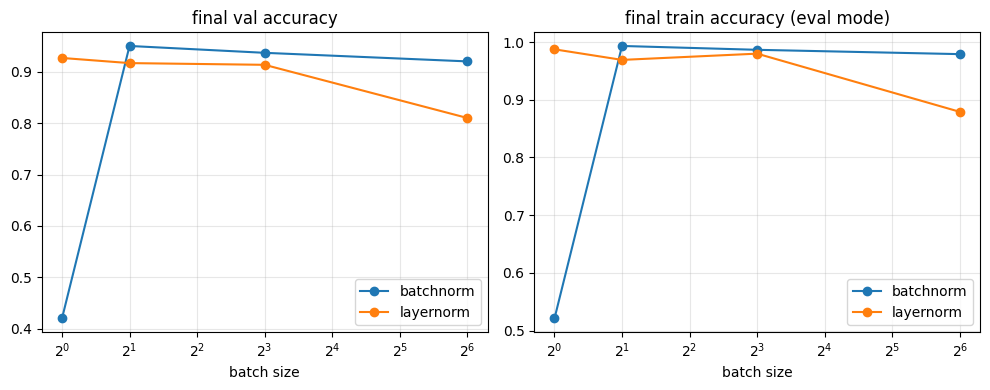

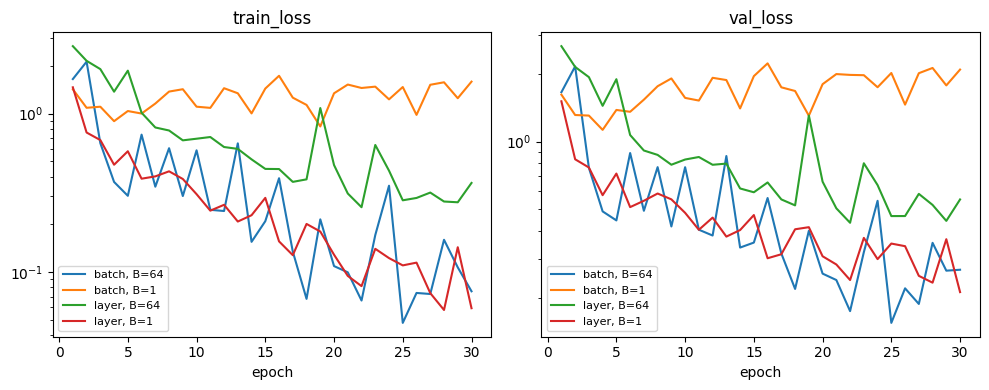

In [11]:
%%time
batch_sizes = [64, 8, 2, 1]
norm_histories = {}
# TODO: for norm in ["batch", "layer"] and each batch size B: set the seed, build the SmallCNN (best_dropout, norm),
# train for 30 epochs with batch_size=B and an SGD optimizer with lr = LR_SGD * B / 64 and weight_decay=best_wd.
# Store the history in norm_histories[(norm, B)] and print summarize(...).

# the code below plots the results from norm_histories
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for norm in ["batch", "layer"]:
    axes[0].plot(batch_sizes, [norm_histories[(norm, B)]["val_acc"][-1] for B in batch_sizes], "-o", label=f"{norm}norm")
    axes[1].plot(batch_sizes, [norm_histories[(norm, B)]["train_acc"][-1] for B in batch_sizes], "-o", label=f"{norm}norm")
axes[0].set_title("final val accuracy"); axes[1].set_title("final train accuracy (eval mode)")
for ax in axes:
    ax.set_xscale("log", base=2); ax.set_xlabel("batch size"); ax.legend(); ax.grid(alpha=0.3)
fig.tight_layout()

compare({f"{norm}, B={B}": norm_histories[(norm, B)] for norm in ["batch", "layer"] for B in [64, 1]}, keys=("train_loss", "val_loss"), ylog=True)

<div class="alert alert-info" role="alert"><b>Analyze your results on the full range of batch sizes in this box.</b>
<ol>
<li>How does the validation accuracy of BatchNorm evolve when the batch size decreases from 64 to 1? At which batch size does it start to degrade and at which does it collapse? Note that in this CNN each channel statistic is computed over the batch <b>and</b> all the spatial positions of the feature map: why does that make BatchNorm more robust than the chapter's description suggests, until the batch gets really small?</li>
<li>At batch size 1 the training accuracy is also bad, even though the loss is optimized on the training set. Explain it with the discrepancy between the statistics used at training time (the current batch) and at test time (the running average) described in chapter 7.</li>
<li>How does LayerNorm evolve when the batch size decreases? Is LayerNorm better or worse than BatchNorm at batch size 64? What does it lose in comparison?</li>
<li>LayerNorm gets <i>better</i> when the batch gets smaller, although it does not depend on the batch at all. Is it an effect of the batch size, or of the learning rate (which is $0.03 \cdot B/64$ and thus smaller for small batches)? Which experiment would you run to find out?</li>
<li>Which normalization would you keep if the batch size were constrained (e.g., by GPU memory on a much bigger model)? And if it were not?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## Optimizers

We now go back to a comfortable batch size of 64, keep BatchNorm (the more common choice for convolutional networks), and investigate the effect of the optimizer itself. The BatchNorm model of Q5 is our baseline (plain SGD, `lr=0.03`).

<div class="alert alert-success"> <b>Q7.</b> Using the best recipe so far (<code>dropout_p=best_dropout</code>, <code>norm="batch"</code>, <code>weight_decay=best_wd</code>, batch size 64), train 80 epochs with <code>SGD</code> with <code>momentum=0.9</code>, (a) with the same learning rate as the plain SGD (0.03) and (b) with the learning rate divided by $1/(1-m)=10$ (0.003). Compare the loss curves to plain SGD.
</div>

SGD, lr=0.03                   train acc=0.995 | val acc=0.950 | val loss=0.155 | epochs to train loss<0.3: 9 | std val loss (last 20): 0.193 | 9s
SGD+momentum, lr=0.03          train acc=0.893 | val acc=0.850 | val loss=0.408 | epochs to train loss<0.3: 14 | std val loss (last 20): 0.317 | 10s
SGD+momentum, lr=0.003         train acc=1.000 | val acc=0.970 | val loss=0.116 | epochs to train loss<0.3: 5 | std val loss (last 20): 0.020 | 10s
CPU times: user 19.3 s, sys: 105 ms, total: 19.4 s
Wall time: 19.5 s


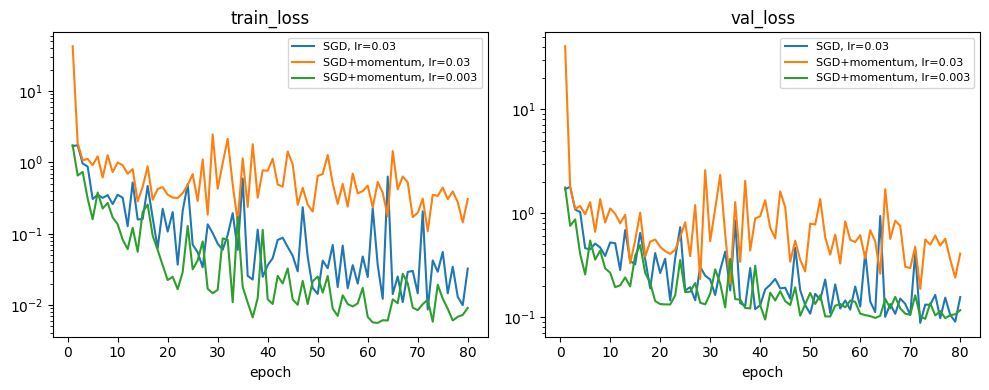

In [12]:
%%time
momentum_histories = {"SGD, lr=0.03": history_bn}
# TODO: train the BatchNorm SmallCNN (best_dropout) for 80 epochs with SGD(momentum=0.9, weight_decay=best_wd) for
# lr=0.03 and for lr=0.003. Store the histories in momentum_histories under the names "SGD+momentum, lr=0.03" and
# "SGD+momentum, lr=0.003", and keep the name `history_mom` for the lr=0.003 run: later questions use it.

# TODO: compare the three runs (log scale) and print summarize(...) for each

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>With the same learning rate as plain SGD, what happens when you add momentum? Chapter 7 states that with momentum the magnitude of the update grows to $1/(1-m)$ times the gradient: what is the effective learning rate here compared to the stability region of plain SGD?</li>
<li>With the learning rate rescaled by $(1-m)$, is momentum faster than plain SGD (epochs to reach a given loss)? Is it smoother? Does it change the final accuracy?</li>
<li>Chapter 7 motivates momentum by noisy gradients on rarely-updated parameters. Does the loss curve of the rescaled run look less noisy than the plain SGD one?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

<div class="alert alert-success"> <b>Q8.</b> Replace <code>SGD + momentum</code> with <code>AdamW</code> (learning rate $10^{-3}$, constant), same other hyper-parameters, 80 epochs. <b>Careful with the weight decay:</b> in <code>AdamW</code>, the decay is decoupled from the gradient and each step shrinks the weights by a factor $(1 - \eta\lambda)$, where $\eta$ is the learning rate of the optimizer. To obtain the same shrinkage per step as the SGD runs ($\eta_{SGD}\cdot$<code>best_wd</code>), use <code>weight_decay = best_wd * lr_sgd / lr_adam</code>. Compare all three optimizers (plain SGD, SGD + momentum, AdamW).
</div>

AdamW weight decay: 0.3


SGD                            train acc=0.995 | val acc=0.950 | val loss=0.155 | epochs to train loss<0.3: 9 | std val loss (last 20): 0.193 | 9s
SGD + momentum                 train acc=1.000 | val acc=0.970 | val loss=0.116 | epochs to train loss<0.3: 5 | std val loss (last 20): 0.020 | 10s
AdamW                          train acc=1.000 | val acc=0.977 | val loss=0.095 | epochs to train loss<0.3: 4 | std val loss (last 20): 0.071 | 10s
CPU times: user 9.97 s, sys: 77.9 ms, total: 10 s
Wall time: 10.3 s


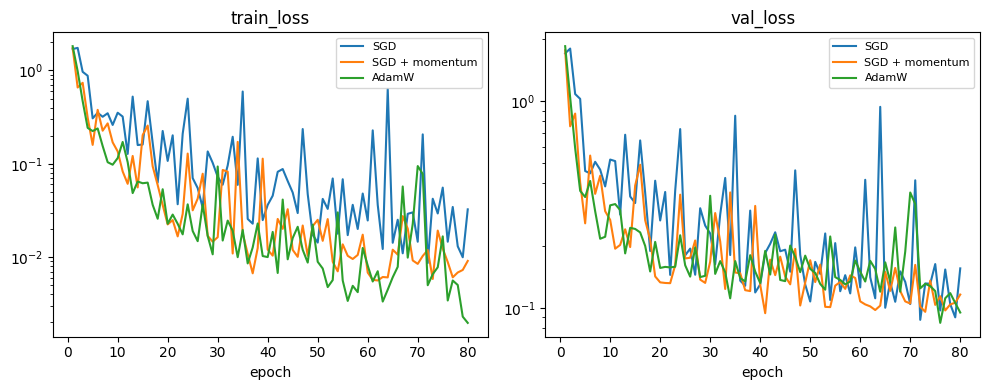

In [13]:
%%time
LR_ADAM = 1e-3
wd_adam = best_wd * LR_SGD / LR_ADAM
print("AdamW weight decay:", wd_adam)

# TODO: train the same BatchNorm SmallCNN (best_dropout) for 80 epochs with torch.optim.AdamW(lr=LR_ADAM, weight_decay=wd_adam)
# (keep the name `history_adamw`)

# TODO: compare plain SGD (history_bn), SGD + momentum (history_mom) and AdamW, and print summarize(...) for each

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Which optimizer converges fastest in number of epochs (look at the first 10 epochs)? Is it the one you would expect from chapter 7?</li>
<li>Look at the second half of the training. Rank the three optimizers by the noise of their validation curve (std of the validation loss over the last 20 epochs). Chapter 7 notes that Adam normalizes the step by the magnitude of the gradients: what does that imply for its step size towards the end of training, when the gradients are small, with a constant learning rate?</li>
<li>Given this, would you conclude from the <i>final</i> validation numbers alone that one optimizer is better than another? What does it tell you about how to compare optimizers fairly?</li>
<li>Why does the weight decay of AdamW have to be scaled by the learning rate to be comparable with the one of SGD? (Hint: exercise on weight decay and Adam in chapter 7.) What would happen with Adam and <code>weight_decay=best_wd</code> implemented as an $\ell_2$ penalty added to the loss?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## Learning rate schedule

The dilemma of a constant learning rate (chapter 7) is that it is fast at the beginning but unstable towards the end. A decaying learning rate stabilizes the training; the most successful one is the cosine decay, preceded by a linear warmup phase that makes higher peak learning rates stable.

<div class="alert alert-success"> <b>Q9.</b> Implement the cosine schedule with warmup of chapter 7 as a function <code>cosine_with_warmup(t, warmup_steps, total_steps)</code> that returns the factor, between 0 and 1, to apply to the peak learning rate at step $t$: it grows linearly from 0 to 1 over <code>warmup_steps</code>, then follows a half cosine down to 0 at <code>total_steps</code>. PyTorch applies it with <code>torch.optim.lr_scheduler.LambdaLR(optimizer, lambda t: cosine_with_warmup(t, warmup_steps, total_steps))</code>, and <code>train_model</code> steps it after every batch when you pass it as <code>scheduler</code>. Retrain the AdamW model of Q8 (peak learning rate $10^{-3}$, then also $3\cdot 10^{-3}$) with a warmup of 5 epochs and a cosine decay over the 80 epochs, and also the SGD + momentum model of Q7 with the same schedule. Plot the learning rate, and compare the validation loss curves of the constant-learning-rate runs (Q8) and the scheduled ones.
</div>

In [14]:
def cosine_with_warmup(t, warmup_steps, total_steps):
    '''Factor (between 0 and 1) applied to the peak learning rate at step t: linear warmup, then half a cosine.'''
    # TODO: linear warmup from 0 to 1 during `warmup_steps`, then half a cosine from 1 to 0 until `total_steps`
    pass

AdamW 1e-3, constant           train acc=1.000 | val acc=0.977 | val loss=0.095 | epochs to train loss<0.3: 4 | std val loss (last 20): 0.071 | 10s
AdamW 1e-3, cosine             train acc=1.000 | val acc=0.973 | val loss=0.103 | epochs to train loss<0.3: 7 | std val loss (last 20): 0.003 | 10s
AdamW 3e-3, cosine             train acc=1.000 | val acc=0.977 | val loss=0.115 | epochs to train loss<0.3: 4 | std val loss (last 20): 0.003 | 10s
SGD+momentum 3e-3, constant    train acc=1.000 | val acc=0.970 | val loss=0.116 | epochs to train loss<0.3: 5 | std val loss (last 20): 0.020 | 10s
SGD+momentum 3e-3, cosine      train acc=1.000 | val acc=0.977 | val loss=0.102 | epochs to train loss<0.3: 6 | std val loss (last 20): 0.002 | 9s
CPU times: user 29.1 s, sys: 144 ms, total: 29.2 s
Wall time: 29.4 s


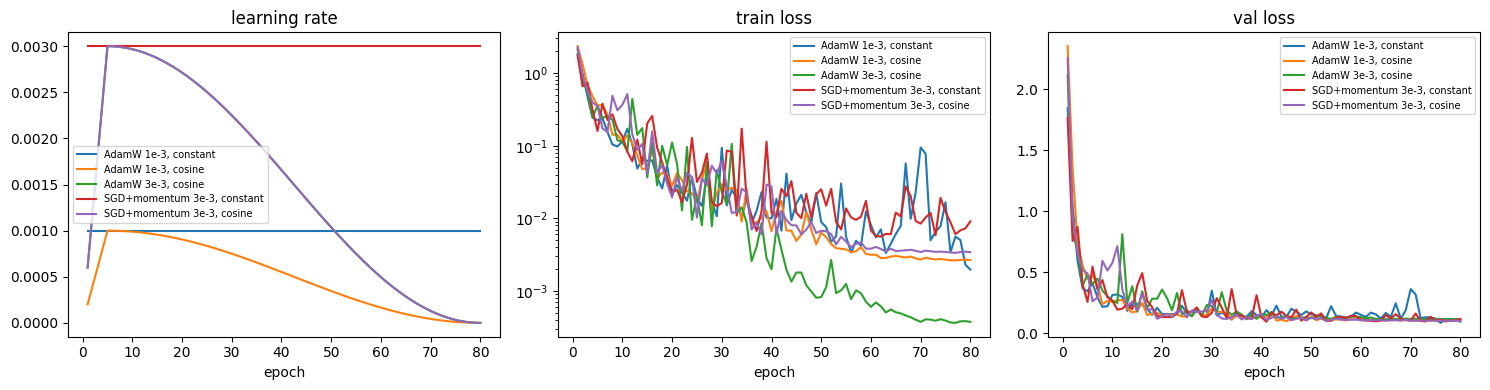

In [15]:
%%time
steps_per_epoch = math.ceil(X_train.shape[0] / 64)
epochs = 80
total_steps, warmup_steps = epochs * steps_per_epoch, 5 * steps_per_epoch

# TODO: build `schedule_histories`, a dict with the 5 runs below (the constant ones were already trained in Q7 and Q8).
# For the scheduled runs: BatchNorm SmallCNN (best_dropout), 80 epochs, and pass
# scheduler=torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_with_warmup(t, warmup_steps, total_steps)) to train_model. For AdamW with a peak lr of 3e-3, scale the weight decay: best_wd * LR_SGD / 3e-3.
#   "AdamW 1e-3, constant"          (history_adamw)
#   "AdamW 1e-3, cosine"
#   "AdamW 3e-3, cosine"
#   "SGD+momentum 3e-3, constant"   (history_mom)
#   "SGD+momentum 3e-3, cosine"     (SGD with momentum 0.9 and lr=0.003)
schedule_histories = {}

# the code below plots the results from schedule_histories
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for name, h in schedule_histories.items():
    axes[0].plot(h["epoch"], h["lr"], label=name)
    axes[1].plot(h["epoch"], h["train_loss"], label=name)
    axes[2].plot(h["epoch"], h["val_loss"], label=name)
axes[0].set_title("learning rate"); axes[1].set_title("train loss"); axes[2].set_title("val loss")
axes[1].set_yscale("log")
for ax in axes:
    ax.set_xlabel("epoch"); ax.legend(fontsize=7)
fig.tight_layout()

for name, h in schedule_histories.items():
    summarize(name, h)

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Compare the AdamW runs with a constant learning rate and with the cosine schedule: what happens to the instability observed at the end of the training (std of the validation loss over the last 20 epochs) and to the final validation loss?</li>
<li>The cosine schedule requires knowing the number of steps in advance (chapter 7). What does it imply for how you would use it in practice, and how does the scaling law at the end of this lab help?</li>
<li>Is the peak learning rate of $3\cdot 10^{-3}$ usable with the schedule? Would you have dared to use it with a constant learning rate? (you can test it)</li>
<li>With both optimizers scheduled, which one is better? Is the difference significant? Is chapter 7's statement that Adam is the standard because it is faster for big networks visible on this small network (look at the first epochs of the training loss)?</li>
<li>Keep AdamW with the cosine schedule (peak learning rate $10^{-3}$) as the recipe for the rest of the lab.</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## Residual connections

Chapter 6 introduces residual connections to let much deeper networks train at all. We finish the architecture part by comparing **plain** CNNs (stacked convolutions, no shortcuts) to the same networks wrapped into **residual blocks**, at several depths, both trained with the final recipe (AdamW, cosine schedule).

The architecture is a small version of the ResNet of chapter 6: a convolutional stem, then 3 stages with channel widths $16 \to 32 \to 64$, each made of `blocks_per_stage` blocks, with a strided convolution (`Downscale`) between stages, global average pooling and a linear classifier. A *block* has two $3\times 3$ convolutions with BatchNorm; the residual block adds its input to its output before the last ReLU, `relu(x + f(x))`.

<div class="alert alert-success"> <b>Q10.</b> Implement the <code>ResBlock</code> described above and its plain counterpart, <code>PlainBlock</code> (same layers, no shortcut), and use the provided <code>DeepCNN</code> to build the two networks for <code>blocks_per_stage</code> in $\{1, 4, 8\}$ (that is 7, 25 and 49 convolutional layers). Train all six with AdamW (peak lr $10^{-3}$, <code>weight_decay=wd_adam</code>) and the cosine schedule (5% warmup) for 30 epochs, and compare plain and residual at each depth.
</div>

In [16]:
class ResBlock(nn.Module):
    '''Two 3x3 convolutions at constant channel count, with a skip connection.'''

    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        # TODO: conv1, bn1, ReLU, conv2, bn2, then add the input and apply a final ReLU
        pass


class PlainBlock(nn.Module):
    '''Same two convolutions as ResBlock, without the shortcut.'''

    def __init__(self, channels):
        super().__init__()
        self.conv1 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn1 = nn.BatchNorm2d(channels)
        self.conv2 = nn.Conv2d(channels, channels, 3, padding=1, bias=False)
        self.bn2 = nn.BatchNorm2d(channels)

    def forward(self, x):
        # TODO: conv1, bn1, ReLU, conv2, bn2, ReLU
        pass

In [17]:
class Downscale(nn.Module):
    '''Strided convolution: changes the channel count and halves the resolution.'''

    def __init__(self, in_channels, out_channels):
        super().__init__()
        self.conv = nn.Conv2d(in_channels, out_channels, 3, stride=2, padding=1, bias=False)
        self.bn = nn.BatchNorm2d(out_channels)

    def forward(self, x):
        return F.relu(self.bn(self.conv(x)))


class DeepCNN(nn.Module):
    '''Stem, then stages of `blocks_per_stage` blocks separated by Downscale; `block_cls` is PlainBlock or ResBlock.'''

    def __init__(self, block_cls, n_classes=12, widths=(16, 32, 64), blocks_per_stage=1, dropout_p=0.0):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, widths[0], 3, padding=1, bias=False),
            nn.BatchNorm2d(widths[0]),
            nn.ReLU(),
        )
        stages = []
        prev_w = widths[0]
        for w in widths:
            if w != prev_w:
                stages.append(Downscale(prev_w, w))
            stages += [block_cls(w) for _ in range(blocks_per_stage)]
            prev_w = w
        self.stages = nn.Sequential(*stages)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.dropout = nn.Dropout(dropout_p)
        self.classifier = nn.Linear(widths[-1], n_classes)

    def forward(self, x):
        x = self.stem(x)
        x = self.stages(x)
        x = self.pool(x).flatten(1)
        x = self.dropout(x)
        return self.classifier(x)


def adamw_cosine(model, epochs, lr=1e-3, wd=None, batch_size=64, warmup_frac=0.05):
    '''The final recipe: AdamW with a cosine schedule and a warmup of `warmup_frac` of the steps.'''
    wd = wd_adam if wd is None else wd
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    total = epochs * math.ceil(X_train.shape[0] / batch_size)
    warmup = max(1, int(warmup_frac * total))
    return opt, torch.optim.lr_scheduler.LambdaLR(opt, lambda t: cosine_with_warmup(t, warmup, total))

plain, 1 blocks/stage (121,692 params) train acc=0.996 | val acc=0.993 | val loss=0.114 | epochs to train loss<0.3: 14 | std val loss (last 20): 0.125 | 10s


residual, 1 blocks/stage (121,692 params) train acc=0.995 | val acc=0.993 | val loss=0.099 | epochs to train loss<0.3: 13 | std val loss (last 20): 0.088 | 11s


plain, 4 blocks/stage (413,340 params) train acc=0.929 | val acc=0.893 | val loss=0.255 | epochs to train loss<0.3: 22 | std val loss (last 20): 0.329 | 32s


residual, 4 blocks/stage (413,340 params) train acc=0.998 | val acc=0.983 | val loss=0.054 | epochs to train loss<0.3: 12 | std val loss (last 20): 0.180 | 35s


plain, 8 blocks/stage (802,204 params) train acc=0.646 | val acc=0.567 | val loss=0.974 | epochs to train loss<0.3: None | std val loss (last 20): 0.429 | 62s


residual, 8 blocks/stage (802,204 params) train acc=0.998 | val acc=0.973 | val loss=0.085 | epochs to train loss<0.3: 12 | std val loss (last 20): 0.207 | 67s


CPU times: user 2min 42s, sys: 56.5 s, total: 3min 39s
Wall time: 3min 38s


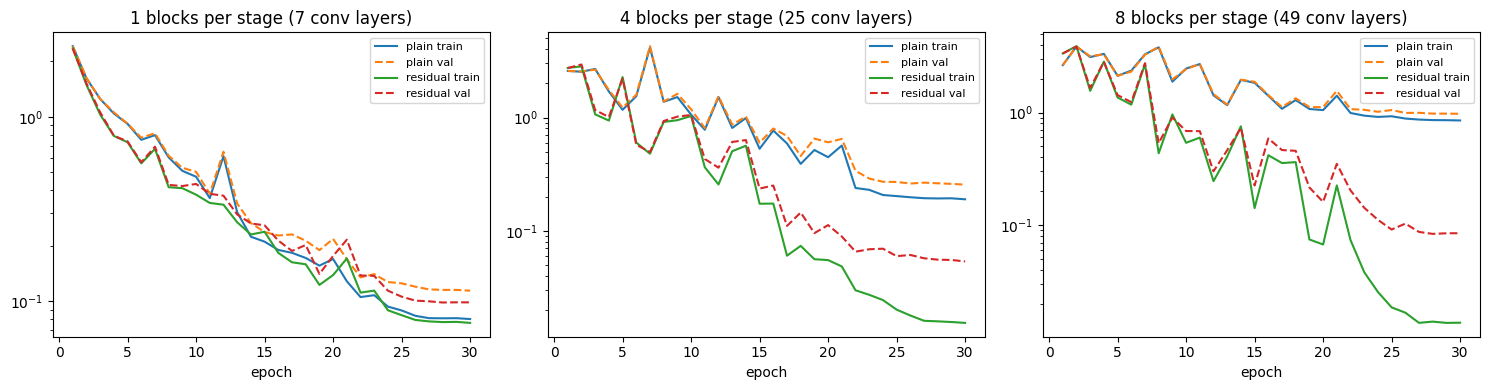

In [18]:
%%time
depth_histories = {}
# TODO: for blocks_per_stage in [1, 4, 8] and for plain and residual blocks: build DeepCNN(block, blocks_per_stage=..., dropout_p=0.2),
# get the optimizer and the scheduler with `opt, sched = adamw_cosine(model, epochs=30)`, train for 30 epochs
# (scheduler=sched). Store the history in depth_histories[(name, blocks_per_stage)] with name "plain" or "residual",
# and print summarize(...).

# the code below plots the results from depth_histories
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, bps in zip(axes, [1, 4, 8]):
    for name in ["plain", "residual"]:
        h = depth_histories[(name, bps)]
        ax.plot(h["epoch"], h["train_loss"], label=f"{name} train")
        ax.plot(h["epoch"], h["val_loss"], "--", label=f"{name} val")
    ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_title(f"{bps} blocks per stage ({6 * bps + 1} conv layers)"); ax.legend(fontsize=8)
fig.tight_layout()

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>At the shallowest depth (7 layers), is there any difference between the plain and the residual network? Explain it with chapter 7's discussion of BatchNorm and the stability of the gradients.</li>
<li>What happens to the plain network when the depth increases to 25 and 49 layers? Look at the <b>training</b> loss and accuracy, not only the validation ones: is it overfitting, or is it unable to optimize? This is the degradation problem of chapter 6.</li>
<li>What is the behavior of the residual network when the depth increases? Using the formula $x_{l+1} = h_l(x_l) + x_l$ of chapter 6, explain why its gradient does not vanish.</li>
<li>A deeper plain network contains the shallower one as a special case (the extra layers could learn the identity), and yet it trains worse. What does it say about optimization versus capacity?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

## A mini scaling law

Chapter 7 shows that the best validation loss reached by a family of models can bit approximated by a power law of the training compute, and uses it to decide how big a model is worth training for a given budget. We reproduce a small version of this on Bluebell with the residual network of Q10 (1 block per stage), trained with the final recipe.

We need a measure of compute. Instead of a proxy, we count the floating point operations (FLOPs) of the model with `torch.utils.flop_counter.FlopCounterMode`. Chapter 6 states that back-propagation costs at most 3 times a forward pass, so one training step on $n$ samples costs about $3 \times n \times$ (FLOPs of a forward pass on one sample).

Remember that the cosine schedule needs to know the total number of steps in advance: **a run trained for 16 epochs is not the same as the first 16 epochs of a run trained for 64 epochs.** Each point of the scaling law is therefore a separate training run, with its own schedule, for a given width and a given number of epochs.

<div class="alert alert-success"> <b>Q11.</b> For the width multipliers $\{0.25, 0.5\}$ (channels $(16, 32, 64) \times$ multiplier, rounded), and the training budgets <code>[2, 4, 8, 16, 32, 64, 128]</code> epochs (up to 256 for the smallest width, which is cheap), train the residual network (<code>blocks_per_stage=1</code>, <code>dropout_p=0.2</code>: the feature vector fed to the classifier has only 16 to 32 dimensions, so we use a lower dropout than in Q4) with the final recipe (AdamW, cosine, peak lr $10^{-3}$), on 2 seeds. Record the final validation loss (mean over the two seeds) and the total training FLOPs of each run. Plot the validation loss against the FLOPs on a log-log scale, one curve per width, and draw the <b>compute-optimal frontier</b>: the best validation loss reached by <i>any</i> width at a given compute budget (the lower envelope of all the points). Fit a power law $L = a \cdot C^{b}$ (a straight line in log-log scale) to the frontier.
</div>

In [19]:
def width_channels(mult, base=(16, 32, 64)):
    return tuple(max(1, round(c * mult)) for c in base)


def make_res_net(mult):
    return DeepCNN(ResBlock, widths=width_channels(mult), blocks_per_stage=1, dropout_p=0.2).to(device)


def train_flops(model, epochs, n_samples=X_train.shape[0]):
    '''Total FLOPs of training: 3 x (forward FLOPs of one sample) x samples x epochs.'''
    model.eval()
    with FlopCounterMode(display=False) as counter:
        model(X_train[:1])
    return 3 * counter.get_total_flops() * n_samples * epochs


def run_point(mult, epochs, seeds):
    '''One point of the scaling law: mean final val loss over seeds, and total training FLOPs.'''
    losses = []
    for seed in seeds:
        set_seed(seed)
        model = make_res_net(mult)
        opt, sched = adamw_cosine(model, epochs)
        h = train_model(model, opt, epochs, scheduler=sched, log_every=0, eval_every=epochs)
        losses.append(h["val_loss"][-1])
    return {"mult": mult, "epochs": epochs, "flops": train_flops(model, epochs),
            "val_loss": float(np.mean(losses)), "params": count_parameters(model)}

In [20]:
%%time
seeds = [SEED, SEED + 1]
budgets = {0.25: [2, 4, 8, 16, 32, 64, 128, 256], 0.5: [2, 4, 8, 16, 32, 64, 128]}

points = []
# TODO: for each width multiplier and each number of epochs, compute a point with run_point(mult, epochs, seeds), append it
# to `points` (a list of dicts) and print its width, epochs, FLOPs and val loss

width x0.25,   2 epochs: FLOPs=6.58e+10, val loss=2.233


width x0.25,   4 epochs: FLOPs=1.32e+11, val loss=1.940


width x0.25,   8 epochs: FLOPs=2.63e+11, val loss=1.672


width x0.25,  16 epochs: FLOPs=5.27e+11, val loss=1.280


width x0.25,  32 epochs: FLOPs=1.05e+12, val loss=0.857


width x0.25,  64 epochs: FLOPs=2.11e+12, val loss=0.493


... (5 outputs left out)

width x0.5,  16 epochs: FLOPs=2.00e+12, val loss=0.642


width x0.5,  32 epochs: FLOPs=4.01e+12, val loss=0.299


width x0.5,  64 epochs: FLOPs=8.02e+12, val loss=0.134


width x0.5, 128 epochs: FLOPs=1.60e+13, val loss=0.070
CPU times: user 2min 34s, sys: 31.5 s, total: 3min 5s
Wall time: 3min 7s


power law on the frontier: val loss = 3.55e+07 * C^(-0.643)


Text(0.5, 1.0, 'A mini scaling law on Bluebell')

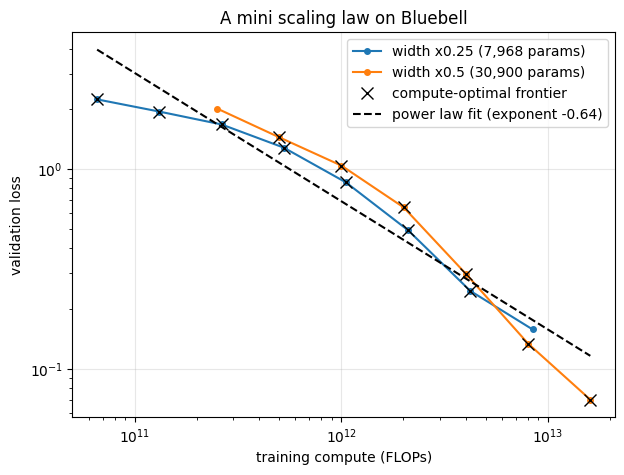

In [21]:
def frontier_of(points):
    '''Compute-optimal frontier: returns the list of points (sorted by FLOPs) that improve on every cheaper point.'''
    # TODO:
    pass


def fit_power_law(frontier):
    '''Least-squares fit of log L = log a + b log C on the frontier; returns (a, b) of L = a * C^b.'''
    # TODO: (hint: np.polyfit on the logs)
    pass


frontier = frontier_of(points)
a, b = fit_power_law(frontier)
print(f"power law on the frontier: val loss = {a:.3g} * C^({b:.3f})")

# the code below plots the points, the frontier and the fit
fig, ax = plt.subplots(figsize=(7, 5))
for mult in budgets:
    pts = sorted((p for p in points if p["mult"] == mult), key=lambda p: p["flops"])
    ax.plot([p["flops"] for p in pts], [p["val_loss"] for p in pts], "-o", ms=4, label=f"width x{mult} ({pts[0]['params']:,} params)")
ax.plot([p["flops"] for p in frontier], [p["val_loss"] for p in frontier], "kx", ms=9, label="compute-optimal frontier")
C = np.logspace(np.log10(frontier[0]["flops"]), np.log10(frontier[-1]["flops"]), 50)
ax.plot(C, a * C ** b, "k--", label=f"power law fit (exponent {b:.2f})")
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xlabel("training compute (FLOPs)"); ax.set_ylabel("validation loss"); ax.legend(); ax.grid(alpha=0.3)
ax.set_title("A mini scaling law on Bluebell")

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>At the smallest compute budgets, which width is the most efficient (lowest loss for the compute spent)? Does the ranking change at larger budgets? At which compute does the frontier switch from one width to the other?</li>
<li>Chapter 7 states that continuing to train a small model is a waste of resources at large budget and one should increase the model size instead. Do you see the curve of the smaller width flattening relative to the larger one?</li>
<li>How well does a straight line in log-log scale fit the frontier? Is it valid at every compute budget? What is the value of the exponent, and what does it say about the cost of reducing the loss by a factor 2?</li>
<li>We ran only 2 seeds per point, whereas chapter 7's figure uses 30. Where do you see the effect of the seed noise in your plot?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>

The goal of a scaling law is to **predict** the outcome of an experiment that is too expensive to run blindly. We have only used cheap models (widths $\times 0.25$ and $\times 0.5$, at most $\approx 10^{13}$ FLOPs). Suppose now that we want to reach a validation loss of $L^\star = 0.04$ and that we plan to use the $\times 1$ width (twice the channels of the $\times 0.5$, hence 4 times the FLOPs per epoch: a much more expensive model that is not in the previous plot).

<div class="alert alert-success"> <b>Q12.</b> Using only the power law of Q11 (do not train anything first), (a) predict the training compute $C^\star$ needed to reach $L^\star = 0.04$; (b) convert it into a number of epochs for the $\times 1$ width (divide by the FLOPs of one epoch of this model); (c) train the $\times 1$ model for that number of epochs with the final recipe (2 seeds) and compare the validation loss you obtain to the target. Add the point to the scaling plot. (d) By how much would the prediction have been off if you had trained for half or twice as many epochs?
</div>

(a) predicted compute to reach val loss 0.04: C* = 8.40e+13 FLOPs
(b) FLOPs of one epoch of the x1 model: 4.88e+11 -> 172 epochs


(c) x1 model,  86 epochs: FLOPs=4.20e+13, predicted frontier loss=0.062, measured val loss=0.043


(c) x1 model, 172 epochs: FLOPs=8.40e+13, predicted frontier loss=0.040, measured val loss=0.035


(c) x1 model, 344 epochs: FLOPs=1.68e+14, predicted frontier loss=0.026, measured val loss=0.034
CPU times: user 3min 44s, sys: 2min, total: 5min 44s
Wall time: 5min 50s


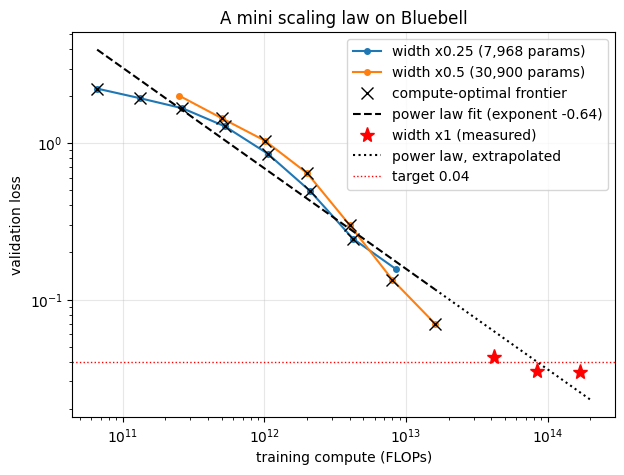

In [22]:
%%time
target = 0.04
# TODO (a): predicted compute C_star to reach `target`, by inverting the power law
# TODO (b): FLOPs of one epoch of the x1 model (train_flops(make_res_net(1.0), 1)), and the number of epochs `epochs_star`
# TODO (c)+(d): train the x1 model (run_point(1.0, epochs, seeds)) for epochs_star // 2, epochs_star and 2 * epochs_star epochs.
# Keep the three points in `big_points` and, for each, print the predicted frontier loss a * flops ** b next to the measured val loss.
big_points = []

# the code below adds the points to the scaling plot of Q11
ax.plot([p["flops"] for p in big_points], [p["val_loss"] for p in big_points], "r*", ms=11, label="width x1 (measured)")
C_ext = np.logspace(np.log10(frontier[-1]["flops"]), np.log10(2e14), 20)
ax.plot(C_ext, a * C_ext ** b, "k:", label="power law, extrapolated")
ax.axhline(target, color="r", ls=":", lw=1, label=f"target {target}")
ax.legend()
fig

<div class="alert alert-info" role="alert"><b>Analyze your results in this box.</b>
<ol>
<li>Did the $\times 1$ model trained for the predicted number of epochs reach the target validation loss? What is the relative error between the predicted and the measured loss, and between the predicted compute and the compute that was really needed?</li>
<li>The scaling law was fit on models whose cost per epoch is 4 to 15 times smaller than the $\times 1$ model and on budgets up to $\approx 10^{13}$ FLOPs. How far can we trust the extrapolation? What do you expect to happen if we ask for a target of $0.01$? (Hint: chapter 7 mentions that scaling laws are robust for a few orders of magnitude, but what is the minimum validation loss that a model trained on 1200 images can reach?)</li>
<li>Which of the two quantities, compute or model size, does the scaling law choose for you? What additional experiments would you need to also decide the size of the model for a given compute budget?</li>
<li>Chapter 7 argues that it is better to spend a significant part of the budget on such a mini scaling law and then train a single large model, than to try 2-3 large runs blindly. With the numbers of this lab (cost of the Q11 sweep vs. cost of the $\times 1$ run), is this argument convincing here? Would it be at 1000 times the scale?</li>
</ol>
<b>Your answer:</b>
<br><br><br>
</div>